Environment

In [1]:
libs = {
    "hypernet": "/home/zanardi/Codes/TC/HyperNet/hypernet",
    "pycomet": "/home/zanardi/Codes/ML/PyCOMET/pycomet"
}

In [2]:
import sys
for lib in libs.values():
    sys.path.append(lib)

Import libraries

In [3]:
import os
import json
import pycomet
import numpy as np
import tensorflow as tf

from scipy.linalg import expm
from silx.io.dictdump import h5todict

from hypernet import const
from hypernet.apps import utils as hyputils
from pycomet.networks import NodePartitionFunctions, EdgeBackward, LinearMEGraphNet

Plotting

In [4]:
import matplotlib
from matplotlib import pyplot as plt
COLORS = matplotlib.rcParams['axes.prop_cycle'].by_key()['color']

path_to_figs = "./figs/"
os.makedirs(path_to_figs, exist_ok=True)

def plot_var(
    x,
    y,
    xref=None,
    yref=None,
    labels=[r'$t$ [s]', r'$X$'],
    scales=['log', 'log'],
    names=None,
    figname=None
):
    # Initialize figures
    fig = plt.figure()
    ax = fig.add_subplot()
    # x axis
    xlim = [np.amin(x), np.amax(x)]
    ax.set_xlim(xlim)
    ax.set_xlabel(labels[0])
    ax.set_xscale(scales[0])
    # y axis
    ax.set_ylabel(labels[1])
    ax.set_yscale(scales[1])
    # Plotting
    true_style = dict(
        lw=1
    )
    pred_style = dict(
        marker='^',
        fillstyle='none',
        markersize=5,
        markevery=y.shape[0]//20,
        ls='--',
        lw=1
    )
    for d in range(y.shape[1]):
        ax.plot(x, y[:,d], c=COLORS[d], **pred_style)
        ax.plot(xref, yref[:,d], c=COLORS[d], label=names[d], **true_style)
    plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
    plt.legend()
    if (figname is not None):
        fig.savefig(figname)
    plt.show()
    plt.close()

Initializing thermophysical models

In [5]:
with open("./../physics/inputs.json") as file:
    phyinp = json.load(file)
# Species thermo
sp_th = hyputils._get_specie_thermos(phyinp)
# Mixture
mix = hyputils._get_mixture(phyinp, sp_th)
# Kinetics
kin = hyputils._get_kinetics(phyinp, sp_th, mix)

Numerical solution

In [6]:
sol = h5todict(h5file='./../physics/solution.hdf5')

In [7]:
na, nm = [sol[f"X_{s}"] * sol['n'] for s in sp_th.keys()]

In [8]:
# Compute source term
t, T = [sol[k] for k in ('t', 'T')]
n = np.hstack([na, nm])
omega = kin.function(t=t, y=[n, T])
dnmdt = omega[:,1:-1] / const.UNA
dnmdt = dnmdt.numpy().squeeze()

Analytical solution

In [9]:
# Solution function
nm_int = lambda t, n0, k: np.matmul(expm(k*t), n0)

In [10]:
# Construct the evolution matrix
kf, kb = 0.0, 0.0
for reaction in kin.reactions:
    kf = kf + reaction.fwd.k.numpy().squeeze()[0]
    kb = kb + reaction.bwd.k.numpy().squeeze()[0]
k = kb.T + kf
k = (k.T - np.diag(np.sum(k, axis=-1))) * na[0]
# Compute exact solution
nm_anal = np.vstack([nm_int(ti, nm[0], k) for ti in t])
# Compute source term
dnmdt_anal = np.einsum("ij,nj->ni",k,nm_anal) / const.UNA

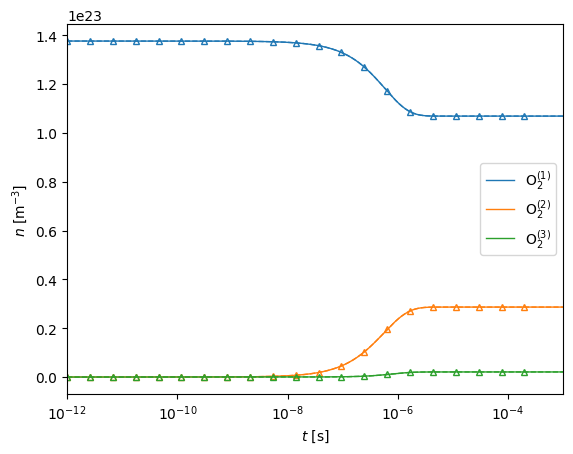

In [11]:
plot_var(
    x=t.squeeze()[1:],
    y=nm[1:],
    xref=t.squeeze()[1:],
    yref=nm_anal[1:],
    labels=[r'$t$ [s]', r'$n$ [m$^{-3}$]'],
    scales=['log', 'linear'],
    names=[r'O$_2^{(%d)}$' % (i+1) for i in range(dnmdt.shape[1])],
    figname=path_to_figs + "/solution"
)

Construct graph

In [36]:
# Nodes
node_attr = nm[...,None]
# Edges
k = kf + kb.T
k_idx = np.where(k > 0)
edge_index = np.array(k_idx)
edge_attr = (k[k_idx] * na[0]).reshape(1,-1,1)
edge_attr = np.tile(edge_attr, (len(node_attr),1,1))
# Graph
graph = [node_attr[:2], edge_attr[:2]]
graph = tf.nest.map_structure(tf.convert_to_tensor, graph)

Load linear master equation graph model

In [37]:
lays_args = {

    "node_pf": {
        "lay_id": "NodePartitionFunctions",
        "kwargs": {
            "node_index_temp": {
                "int": 3,
                "chem": 2,
                "trans": 2
            },
            "specie_thermos": {
                "filename": "./data/sp_th.json",
                "thermo_process": 0,
                "eos_model": "PerfectGas"
            }
        }
    },

    "edge_bwd": {
        "lay_id": "EdgeBackward",
        "kwargs": {
            "node_index_pf": [4],
            "static_fwd_edge_index": "./data/fwd_edge_index.txt"
        }
    },

    "lin_me_gnet": {
        "lay_id": "LinearMEGraphNet",
        "kwargs": {
            "node_attr_indices": [1],
            "static_edge_index": "./data/fwd_edge_index.txt"
        }
    }

}

In [38]:
tf.keras.backend.clear_session()

lays = {
    # "node_pf": NodePartitionFunctions(**lays_args["node_pf"]["kwargs"]),
    # "edge_bwd": EdgeBackward(**lays_args["edge_bwd"]["kwargs"]),
    "lin_me_gnet": LinearMEGraphNet(**lays_args["lin_me_gnet"]["kwargs"])
}

# def call(graph, training=False):
#     graph = tf.nest.map_structure(tf.identity, graph)
#     # Node partition functions
#     graph[0] = lays["node_pf"](graph[0], training=training)
#     # Edge backward
#     graph = lays["edge_bwd"](graph, training=training)
#     # Graph processor
#     return lays["lin_me_gnet"](graph, training=training)

def call(graph, training=False):
    # Graph processor
    return lays["lin_me_gnet"](graph, training=training)

In [28]:
# # Nodes
# nb_nodes = nm.shape[-1]
# node_t = np.tile(t.reshape(-1,1,1), (1,nb_nodes,1))
# node_n = nm[...,None]
# node_T = np.tile(T.reshape(-1,1,1), (1,nb_nodes,2))
# node_attr = np.concatenate([node_t, node_n, node_T], axis=-1)
# # Edges
# k_idx = np.where(kf > 0)
# edge_index = tf.convert_to_tensor(np.array(k_idx))
# edge_attr = (kf[k_idx] * na[0]).reshape(1,-1,1)
# edge_attr = np.tile(edge_attr, (len(node_attr),1,1))
# # Graph
# graph = [node_attr[:2,:,1:2], edge_attr[:2]]
# graph = tf.nest.map_structure(tf.convert_to_tensor, graph)

In [39]:
inp = tf.nest.map_structure(lambda x: tf.keras.Input(tuple(x.shape[1:])), graph)
out = call(inp)
model = tf.keras.Model(inp, out)
inp

[<KerasTensor: shape=(None, 3, 1) dtype=float64 (created by layer 'input_1')>,
 <KerasTensor: shape=(None, 6, 1) dtype=float64 (created by layer 'input_2')>]

In [46]:
G = tf.nest.map_structure(tf.squeeze, graph)
print(G[0].shape)
with tf.GradientTape(persistent=True) as g:
  g.watch(G[0])
  G = tf.nest.map_structure(lambda x: tf.expand_dims(x, axis=-1), G)
  y = tf.nest.map_structure(tf.squeeze, model(G))
  print(y.shape)
dy_dx = g.batch_jacobian(
  y,
  G[0],
  unconnected_gradients=tf.UnconnectedGradients.NONE
)
print(dy_dx.shape)
print((dy_dx.numpy() != 0.0).any())
dy_dx

(2, 3)
(2, 3)
(2, 3, 3, 1)
True


<tf.Tensor: shape=(2, 3, 3, 1), dtype=float64, numpy=
array([[[[ -388307.41237457],
         [ 1427887.3140588 ],
         [  278155.66390996]],

        [[  382877.2909964 ],
         [-1652637.95572571],
         [ 3087059.38446161]],

        [[    5430.12137817],
         [  224750.64166691],
         [-3365215.04837156]]],


       [[[ -388307.41237457],
         [ 1427887.3140588 ],
         [  278155.66390996]],

        [[  382877.2909964 ],
         [-1652637.95572571],
         [ 3087059.38446161]],

        [[    5430.12137817],
         [  224750.64166691],
         [-3365215.04837156]]]])>

In [ ]:
dnmdt_pred = call(graph=[node_attr, edge_attr])
dnmdt_pred = dnmdt_pred.numpy().squeeze()

In [ ]:
plot_var(
    x=t.squeeze()[1:],
    y=dnmdt_pred[1:],
    xref=t.squeeze()[1:],
    yref=dnmdt[1:],
    labels=[r'$t$ [s]', r'$\omega$ [m$^{-3}$s$^{-1}$]'],
    scales=['log', 'linear'],
    names=[r'O$_2^{(%d)}$' % (i+1) for i in range(dnmdt.shape[1])],
    figname=path_to_figs + "/source"
)